# **Soko Regional Performance & Delivery Analytics**

## Project Overview

The project analyses Soko a ficticious Ecommerce platform to understand inconsistent revenue growth across regions and a rising number of cancelled and returned orders.

In [2]:
# Import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# load the data
df = pd.read_csv("D:/SQL/Practice Course Materials/KeData Labs/Python/Python for Data Analytics & Data Apps/Soko Ecommerce Analysis/kenya_ecommerce_sales_raw.csv")


## **Data Inspection**

In [4]:
# Inspect the data
df.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue,order_status
0,31832,9/27/2023,50089,Electronics,Coast,1,40828.15,0.10,Card,6.0,NaN,36745.34,Delivered
1,30269,2/8/2023,50224,Beauty & Personal Care,Coast,1,3496.14,0.09,M-Pesa,5.0,4.2,3181.49,Delivered
2,32443,12/28/2023,51549,Fashion & Clothing,Rift Valley,7,549.52,0.11,M-Pesa,7.0,4.5,3423.51,Delivered
3,33778,7/5/2024,51883,Fashion & Clothing,Western,3,4565.19,0.18,Cash on Delivery,5.0,5.0,11230.37,Delivered
4,30643,4/2/2023,50322,Beauty & Personal Care,Nairobi,2,1384.91,0.03,M-Pesa,6.0,3.5,2686.73,Delivered


In [5]:
df.sample(10)

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue,order_status
4495,31634,8/27/2023,51178,Fashion & Clothing,Coast,6,4985.16,0.10,M-Pesa,7.0,4.1,26919.86,Delivered
323,30701,4/11/2023,51861,Home & Living,Western,3,12212.79,0.14,M-Pesa,7.0,3.2,31509.00,Delivered
1338,32014,10/24/2023,50727,Electronics,Nyanza,7,54902.64,0.07,M-Pesa,5.0,NaN,357416.19,Delivered
2933,32956,3/14/2024,51690,Home & Living,Nairobi,2,15316.15,0.09,M-Pesa,3.0,5.0,27875.39,Delivered
3713,33137,4/9/2024,50083,Fashion & Clothing,Nairobi,7,2187.96,0.08,Airtel Money,1.0,5.0,14090.46,Delivered
3319,32227,11/25/2023,51697,Fashion & Clothing,Nairobi,4,6212.86,0.06,M-Pesa,7.0,5.0,23360.35,Delivered
2428,33019,3/22/2024,52167,Electronics,Nyanza,1,36711.76,0.06,Card,9.0,3.5,34509.05,Delivered
4216,30911,5/12/2023,51043,Electronics,Western,4,7799.78,0.17,M-Pesa,6.0,NaN,25895.27,Delivered
4066,31545,8/13/2023,50975,Groceries,Nairobi,7,946.04,0.06,Airtel Money,4.0,4.0,6224.94,Returned
1931,34399,10/6/2024,51859,Groceries,Eastern,1,1693.19,0.12,Card,8.0,3.9,1490.01,Returned


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5008 entries, 0 to 5007
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5008 non-null   int64  
 1   order_date        5008 non-null   str    
 2   customer_id       5008 non-null   int64  
 3   product_category  5008 non-null   str    
 4   region            5008 non-null   str    
 5   quantity          5008 non-null   int64  
 6   unit_price        5008 non-null   str    
 7   discount          5008 non-null   float64
 8   payment_method    5008 non-null   str    
 9   delivery_days     4382 non-null   float64
 10  customer_rating   3835 non-null   str    
 11  revenue           5008 non-null   float64
 12  order_status      5008 non-null   str    
dtypes: float64(3), int64(3), str(7)
memory usage: 788.7 KB


In [7]:
df.dtypes

order_id              int64
order_date              str
customer_id           int64
product_category        str
region                  str
quantity              int64
unit_price              str
discount            float64
payment_method          str
delivery_days       float64
customer_rating         str
revenue             float64
order_status            str
dtype: object

There are data type issues with columns such as order_date, unit_price & customer_rating. 
Missing values also exists in delivery_days(626 rows) and customer_rating(1,173 rows)

In [8]:
df.isna().sum()


order_id               0
order_date             0
customer_id            0
product_category       0
region                 0
quantity               0
unit_price             0
discount               0
payment_method         0
delivery_days        626
customer_rating     1173
revenue                0
order_status           0
dtype: int64

There are no nulls in the dataset

In [9]:
df.describe(include='all')

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue,order_status
count,5008.000000,5008,5008.000000,5008,5008,5008.000000,5008,5008.000000,5008,4382.000000,3835,5008.000000,5008
unique,NaN,840,NaN,5,11,NaN,4982,NaN,9,NaN,45,NaN,4
top,NaN,5/18/2023,NaN,Electronics,Nairobi,NaN,unknown,NaN,M-Pesa,NaN,5.0,NaN,Delivered
freq,NaN,16,NaN,1370,1629,NaN,3,NaN,2985,NaN,841,NaN,4216
mean,32499.290935,NaN,51263.304912,NaN,NaN,4.003994,NaN,0.100026,NaN,5.861935,NaN,45532.392825,NaN
std,1443.324154,NaN,715.926637,NaN,NaN,2.013928,NaN,0.063940,NaN,2.140546,NaN,71400.249683,NaN
min,30001.000000,NaN,50002.000000,NaN,NaN,-7.000000,NaN,0.000000,NaN,1.000000,NaN,210.730000,NaN
25%,31248.750000,NaN,50648.000000,NaN,NaN,2.000000,NaN,0.060000,NaN,4.000000,NaN,6155.585000,NaN
50%,32499.500000,NaN,51255.000000,NaN,NaN,4.000000,NaN,0.090000,NaN,6.000000,NaN,15173.505000,NaN
75%,33748.250000,NaN,51891.000000,NaN,NaN,6.000000,NaN,0.140000,NaN,7.000000,NaN,46956.177500,NaN


#### View duplicated values

In [10]:
## df.duplicated().sum()
df['order_id'].duplicated().sum()

np.int64(8)

#### View total number of unique values per column

In [11]:
df.nunique()

order_id            5000
order_date           840
customer_id         2161
product_category       5
region                11
quantity              10
unit_price          4982
discount              35
payment_method         9
delivery_days         10
customer_rating       45
revenue             4997
order_status           4
dtype: int64

#### Check the individual unique values per column

In [12]:
# Preview to check for inconsistent value types
print(df['region'].unique().value_counts())
print(df['payment_method'].unique().value_counts())



Coast          1
Rift Valley    1
Western        1
Nairobi        1
Nyanza         1
Eastern        1
nairobi        1
Central        1
Nrb            1
 Nairobi       1
NAIROBI        1
Name: count, dtype: int64
Card                1
M-Pesa              1
Cash on Delivery    1
Airtel Money        1
M-PESA              1
mpesa               1
card                1
M PESA              1
Mpesa               1
Name: count, dtype: int64


#### For region the values need to be consistent and this is also applicable to payment method column

In [13]:
df['region'].value_counts()
df['payment_method'].value_counts()

payment_method
M-Pesa              2985
Cash on Delivery     729
Card                 711
Airtel Money         477
M-PESA                27
mpesa                 26
Mpesa                 22
M PESA                17
card                  14
Name: count, dtype: int64

## **Data Cleaning**

In [14]:
# Fix the date types
df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')

In [15]:
print(df['order_date'].isna().sum())

120


In [16]:
# Fill the blank dates that occurred
df = df.sort_values('order_id')
df['order_date'] = df['order_date'].ffill()


#### Fix Unit price column from string to numeric

In [17]:
df['unit_price'] = pd.to_numeric(df['unit_price'], errors='coerce')
df['unit_price'] = df['unit_price'].astype(float)


In [18]:
bad_price = df[df['unit_price'].isna()]
print(bad_price[['order_id', 'unit_price', 'quantity', 'discount', 'revenue']])

      order_id  unit_price  quantity  discount   revenue
1126     31649         NaN         6      0.06  23511.98
257      31747         NaN         1      0.07  57464.76
1184     32736         NaN         7      0.07   5199.28
2395     34028         NaN         1      0.08   5864.21
1257     34641         NaN         5      0.14   6510.50


### Convert customer rating from string to numeric

In [19]:
df['customer_rating'].value_counts()

customer_rating
5.0          841
4.2          148
4.0          145
4.1          145
4.4          140
3.8          139
4.3          139
4.6          139
3.7          137
3.4          136
4.9          136
3.6          135
3.9          129
4.5          129
4.7          128
3.5          118
4.8          118
3.3          106
3.1           88
3.2           87
3.0           72
2.9           63
2.7           60
2.8           51
2.5           48
2.6           45
2.1           36
2.3           32
2.4           31
2.2           22
1.9           19
2.0           17
1.8           10
1.7            8
1.4            6
1.6            6
not rated      5
1.3            4
1.0            4
1.5            4
6.0            3
1.1            3
1.2            1
7.0            1
0.0            1
Name: count, dtype: int64

In [20]:
df['customer_rating'] = pd.to_numeric(df['customer_rating'], errors='coerce')

In [21]:
df['customer_rating'].isna().sum()

np.int64(1178)

### Standardize text across columns

In [22]:
# Remove stray spaces and fix capitals
df['region'] = df['region'].str.strip().str.title()
df['payment_method'] = df['payment_method'].str.strip().str.title()


In [23]:
# Region
df['region'].value_counts()
df['region'] = df['region'].replace({
    'Nrb': 'Nairobi', 
    'nairobi': 'Nairobi',
    'Nairobi': 'Nairobi',
    'NAIROBI': 'Nairobi'})

print(df['region'].value_counts())

region
Nairobi        1679
Rift Valley     791
Coast           710
Central         621
Nyanza          531
Western         364
Eastern         312
Name: count, dtype: int64


In [24]:
# Payment method
df['payment_method'] = df['payment_method'].replace({
    'Mpesa': 'M-Pesa',
    'M pesa': 'M-Pesa',
    'M Pesa': 'M-Pesa',
    'M-pesa': 'M-Pesa'
})

print(df['payment_method'].value_counts())

payment_method
M-Pesa              3077
Cash On Delivery     729
Card                 725
Airtel Money         477
Name: count, dtype: int64


In [25]:
# Product Category 
df['product_category'].str.strip().str.title()
print(df['product_category'].nunique())
print(df['product_category'].value_counts())


5
product_category
Electronics               1370
Fashion & Clothing        1268
Beauty & Personal Care     895
Home & Living              860
Groceries                  615
Name: count, dtype: int64


In [26]:
# Order status
df['order_status'].str.strip().str.title()
print(df['order_status'].nunique())
print(df['order_status'].value_counts())



4
order_status
Delivered    4216
Cancelled     377
Returned      250
Pending       165
Name: count, dtype: int64


### Find and Remove duplicates 

In [27]:
# Order Id column
print(df['order_id'].duplicated().sum())

df =df.drop_duplicates(subset='order_id')
print(df['order_id'].duplicated().sum())

8
0


#### Check for impossible values

In [28]:
# Discount, Unit Price & Revenue
df[['unit_price', 'discount', 'revenue']].describe()

,unit_price,discount,revenue
count,4995.000000,5000.000000,5000.000000
mean,12497.988006,0.100026,45502.140362
std,16692.596670,0.063979,71430.631949
min,0.000000,0.000000,210.730000
25%,2251.055000,0.060000,6155.585000
50%,4640.810000,0.090000,15157.930000
75%,14717.355000,0.140000,46799.827500
max,64814.920000,1.500000,425005.380000


In [29]:
# Delivery days
print(df['delivery_days'].describe())

count    4375.000000
mean        5.860800
std         2.140697
min         1.000000
25%         4.000000
50%         6.000000
75%         7.000000
max        10.000000
Name: delivery_days, dtype: float64


In [30]:
# Missing delivery_days by order status
print(df[df['delivery_days'].isna()]['order_status'].value_counts())

order_status
Cancelled    377
Pending      164
Delivered     84
Name: count, dtype: int64


Blank delivery times belong mostly to Cancelled and Pending orders (541 of 625), which were never delivered. 84 Delivered orders have no recorded time. Left blank, not imputed.

In [31]:
# Customer rating
print(df['customer_rating'].describe())  

# max customer rating is 7. This needs to be corrected so rating can be 1 -5
print((df['customer_rating'] > 5 ).sum())

df.loc[(df['customer_rating'] > 5) | (df['customer_rating'] < 1 ), 'customer_rating'] = None
print(df['customer_rating'].min(), df['customer_rating'].max())

count    3823.000000
mean        4.033115
std         0.867373
min         0.000000
25%         3.400000
50%         4.200000
75%         4.900000
max         7.000000
Name: customer_rating, dtype: float64
4
1.0 5.0


#### Customer rating was set from 1 -5. Ratings above 5 were dropped

In [32]:
# Quantity
print(df['quantity'].describe())

quant = df[df['quantity'] < 0]
print(quant[['order_id', 'quantity', 'unit_price', 'revenue', 'order_status']])

# changes the negative quantity values to positives
df.loc[df['quantity'] < 0, 'quantity'] = df['quantity'].abs()
print(df['quantity'].describe())


count    5000.00000
mean        4.00480
std         2.01375
min        -7.00000
25%         2.00000
50%         4.00000
75%         6.00000
max         7.00000
Name: quantity, dtype: float64
      order_id  quantity  unit_price    revenue order_status
1215     30565        -7     5477.79   34510.08    Delivered
2244     32192        -4     4645.48   16723.73      Pending
3695     32417        -3    58624.08  168837.35    Delivered
1536     33125        -7     4881.29   33485.65    Delivered
2212     34135        -4     9742.53   38580.42    Delivered
count    5000.000000
mean        4.014800
std         1.993734
min         1.000000
25%         2.000000
50%         4.000000
75%         6.000000
max         7.000000
Name: quantity, dtype: float64


In [33]:
# Revenue
df['revenue'].describe()

revenue_check = df['quantity'] * df['unit_price'] * (1 - df['discount'])
print(((revenue_check - df['revenue']).abs() > 1).sum())

# there are 5 rows that revenue doesn't match the above formula

rev_error = df[(revenue_check - df['revenue']).abs() > 1]
print(rev_error[['order_id', 'quantity', 'unit_price', 'discount', 'revenue']]) 

5
      order_id  quantity  unit_price  discount    revenue
715      31659         5        0.00      0.10   13556.97
4334     32050         2        0.00      0.09    8960.79
1508     32542         4    35392.09      1.19  134489.94
3456     33696         5     3504.38      1.30   14543.18
3996     34128         7    44042.23      1.50  289797.87


##### We can see errors from the above rows
1. Two rows have unit price as 0 yet they have revenue 13,556 ad 8,960 respectively. 
2. Three rows have discount which os greater than 1(1.19, 1.30, 1.50). A discount over 1 is impossible

In [34]:
df.loc[df['unit_price'] == 0, 'unit_price'] = df['revenue'] / (df['quantity'] * (1- df['discount']))
df.loc[df['discount'] > 1, 'discount'] = 1 - df['revenue'] / (df['quantity'] * df['unit_price'])

print(df['unit_price'].min())
print(df['discount'].max())

104.39
0.31


In [35]:
# Recheck the revenue column
revenue_check = df['quantity'] * df['unit_price'] * (1 - df['discount'])
print(((revenue_check - df['revenue'].abs() > 1).sum()))  

# 0 mismatches after the fix


0


#### Revenue column now aligns with quantity * unit price * (1-discount) formula

### Final checks before exporting cleaned csv

In [36]:
# Reset the row numbers
df = df.reset_index(drop=True)
df.head(10)

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue,order_status
0,30001,2023-01-01,52362,Beauty & Personal Care,Coast,5,5364.82,0.04,M-Pesa,6.0,2.7,25751.14,Returned
1,30002,2023-01-01,51563,Beauty & Personal Care,Rift Valley,7,4242.98,0.07,M-Pesa,6.0,4.7,27621.80,Delivered
2,30003,2023-01-01,51710,Beauty & Personal Care,Coast,3,2062.43,0.17,M-Pesa,6.0,NaN,5135.45,Delivered
3,30004,2023-01-01,52243,Electronics,Rift Valley,7,61160.38,0.08,M-Pesa,9.0,3.5,393872.85,Delivered
4,30005,2023-01-01,51446,Fashion & Clothing,Rift Valley,4,3374.73,0.04,M-Pesa,NaN,3.8,12958.96,Delivered
5,30006,2023-01-01,51939,Home & Living,Nairobi,6,9241.19,0.11,Cash On Delivery,4.0,5.0,49347.95,Delivered
6,30007,2023-01-01,52084,Groceries,Nyanza,6,2810.39,0.07,Airtel Money,NaN,NaN,15681.98,Pending
7,30008,2023-01-02,50563,Electronics,Nairobi,6,2618.04,0.06,M-Pesa,5.0,3.8,14765.75,Delivered
8,30009,2023-01-02,50139,Electronics,Nairobi,3,48413.27,0.07,M-Pesa,4.0,NaN,135073.02,Delivered
9,30010,2023-01-02,50751,Groceries,Eastern,4,1414.34,0.11,M-Pesa,9.0,4.7,5035.05,Delivered


In [37]:
print(df['order_date'].min(), df['order_date'].max())

2023-01-01 00:00:00 2024-12-31 00:00:00


In [38]:
print(len(df))
print(df.isna().sum())

5000
order_id               0
order_date             0
customer_id            0
product_category       0
region                 0
quantity               0
unit_price             5
discount               0
payment_method         0
delivery_days        625
customer_rating     1182
revenue                0
order_status           0
dtype: int64


## **Export the cleaned data**

In [39]:
# Export as Cleaned csv
df.to_csv("D:/SQL/Practice Course Materials/KeData Labs/Python/Python for Data Analytics & Data Apps/Soko Ecommerce Analysis/kenya_ecommerce_sales_clean.csv", index=False)

clean_csv = pd.read_csv("D:/SQL/Practice Course Materials/KeData Labs/Python/Python for Data Analytics & Data Apps/Soko Ecommerce Analysis/kenya_ecommerce_sales_clean.csv")
print(len(clean_csv))
print(clean_csv.isna().sum())


5000
order_id               0
order_date             0
customer_id            0
product_category       0
region                 0
quantity               0
unit_price             5
discount               0
payment_method         0
delivery_days        625
customer_rating     1182
revenue                0
order_status           0
dtype: int64


## **Feature Engineering**

In [40]:
# Adding year and month columns
df['year'] = df['order_date'].dt.year
df['quarter'] = df['order_date'].dt.quarter

df['month'] = df['order_date'].dt.month

print(df['year'].value_counts().sort_index())
print(df['quarter'].value_counts().sort_index())
print(df['month'].value_counts().sort_index())


year
2023    2469
2024    2531
Name: count, dtype: int64
quarter
1    1237
2    1291
3    1222
4    1250
Name: count, dtype: int64
month
1     396
2     402
3     439
4     438
5     429
6     424
7     414
8     418
9     390
10    428
11    401
12    421
Name: count, dtype: int64


In [41]:
# Grouping the order status columns
# Define any cancelled or returned delivery as lost sales.
df['is_lost'] =df['order_status'].isin(['Cancelled', 'Returned'])        #  checks order_status column and return true if delivered in Cancelled or Returned

print(df['is_lost'].value_counts())


is_lost
False    4374
True      626
Name: count, dtype: int64


Returns **TRUE** if the order was **Cancelled or Returned.** 

Retruns **FALSE** if the order was **Delivered or Pending.**


In [42]:
# Renamed is_lost column to (is_cancelled_or_returned)
df = df.rename(columns={'is_lost': 'is_cancelled_or_returned'})

**Net revenue excludes Cancelled and Returned orders. Pending orders (3.3%) are included, as they haven’t failed.**


In [43]:
# View the is_cancelled_or_returned column
df.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue,order_status,year,quarter,month,is_cancelled_or_returned
0,30001,2023-01-01,52362,Beauty & Personal Care,Coast,5,5364.82,0.04,M-Pesa,6.0,2.7,25751.14,Returned,2023,1,1,True
1,30002,2023-01-01,51563,Beauty & Personal Care,Rift Valley,7,4242.98,0.07,M-Pesa,6.0,4.7,27621.80,Delivered,2023,1,1,False
2,30003,2023-01-01,51710,Beauty & Personal Care,Coast,3,2062.43,0.17,M-Pesa,6.0,NaN,5135.45,Delivered,2023,1,1,False
3,30004,2023-01-01,52243,Electronics,Rift Valley,7,61160.38,0.08,M-Pesa,9.0,3.5,393872.85,Delivered,2023,1,1,False
4,30005,2023-01-01,51446,Fashion & Clothing,Rift Valley,4,3374.73,0.04,M-Pesa,NaN,3.8,12958.96,Delivered,2023,1,1,False


## **Basic Statistics**

#### Statistical summary per column

In [44]:
# View statistics summary
colms = ['quantity', 'unit_price', 'discount', 'delivery_days', 'customer_rating', 'revenue']
print(df[colms].agg(['count', 'sum', 'mean', 'median', 'min', 'max', 'std']).round(2).map('{:,}'.format))


        quantity     unit_price discount delivery_days customer_rating  \
count    5,000.0        4,995.0  5,000.0       4,375.0         3,818.0   
sum     20,074.0  62,435,386.26   496.42      25,641.0        15,393.6   
mean        4.01      12,499.58      0.1          5.86            4.03   
median       4.0       4,642.13     0.09           6.0             4.2   
min          1.0         104.39      0.0           1.0             1.0   
max          7.0      64,814.92     0.31          10.0             5.0   
std         1.99      16,691.61     0.06          2.14            0.86   

               revenue  
count          5,000.0  
sum     227,510,701.81  
mean         45,502.14  
median       15,157.93  
min             210.73  
max         425,005.38  
std          71,430.63  


In [45]:
# Response rate using customer rating column
print('Response rate:', (df['customer_rating'].notna().mean() * 100 ), '%')
print(df['customer_rating'].value_counts().sort_index())

Response rate: 76.36 %
customer_rating
1.0      4
1.1      3
1.2      1
1.3      4
1.4      6
1.5      4
1.6      6
1.7      8
1.8     10
1.9     19
2.0     17
2.1     36
2.2     22
2.3     32
2.4     31
2.5     48
2.6     45
2.7     60
2.8     51
2.9     63
3.0     71
3.1     88
3.2     87
3.3    106
3.4    136
3.5    118
3.6    134
3.7    136
3.8    138
3.9    129
4.0    145
4.1    145
4.2    148
4.3    139
4.4    139
4.5    128
4.6    139
4.7    128
4.8    118
4.9    136
5.0    840
Name: count, dtype: int64


In [46]:
print(df['region'].value_counts(normalize=True) * 100)
print(df['product_category'].value_counts(normalize=True) * 100)
print(df['payment_method'].value_counts(normalize=True) * 100)
print(df['order_status'].value_counts(normalize=True) * 100)


region
Nairobi        33.54
Rift Valley    15.78
Coast          14.14
Central        12.42
Nyanza         10.60
Western         7.28
Eastern         6.24
Name: proportion, dtype: float64
product_category
Electronics               27.34
Fashion & Clothing        25.36
Beauty & Personal Care    17.86
Home & Living             17.14
Groceries                 12.30
Name: proportion, dtype: float64
payment_method
M-Pesa              61.44
Cash On Delivery    14.56
Card                14.48
Airtel Money         9.52
Name: proportion, dtype: float64
order_status
Delivered    84.20
Cancelled     7.54
Returned      4.98
Pending       3.28
Name: proportion, dtype: float64


### **Basic Summary Insights**

1. **Order size**: quantity ranges from 1 to 7 with mean and median both about 4, so orders are small and evenly spread, with no extreme basket sizes.

2. **Prices** are skewed: average unit price is KES 12,502 against a median of 4,641 (about 2.7×), pulled up by Electronics.

3. **Revenue** is skewed: mean order revenue is KES 45,502 against a median of 15,158 (3×, including lost orders). The largest order is about KES 425,000. It’s genuine, because the revenue check matched on every row. Use the median as the “typical order” and explain why.

4. **Regions**: Nairobi has the most orders (33.5%), and Eastern (6.2%) and Western (7.3%) have the fewest.

5. **Categories**: Electronics (27.3%) and Fashion (25.4%) lead by order count, but Electronics is 74% of revenue while Fashion is only about 7%.

4. **Discounts**: average discount is 10% with a maximum of 31%. Effectiveness is not tested yet.

5. **Delivery**: average delivery days is 5.86 days (median 6, range 1 to 10). 4,375 orders (87.5%) have a delivery time.

6. **Response rate**: 76.4% of orders were rated, with an average of 4.03. 5.0 is the single most common score (840 orders). Fewer than 2% of ratings are below rating 2. 

7. **Payment method**: About 71% of orders are paid by mobile money (M-Pesa 61.4%, Airtel Money 9.5%), so findings about payment methods rest mostly on M-Pesa. Card and COD groups are each about 14.5% of orders.

8. **Status**: 84.2% of orders were delivered. Cancelled is 7.5% and Returned is 5.0%, so 12.5% of orders are lost.


## **Analysis**

### **Revenue & Growth drivers**

Filter the data and separate succesful sales from pending/cancelled using 'is_lost' column

In [47]:
# Create sales table
sales = df[df['is_cancelled_or_returned'] == False]
print(len(df), len(sales))

print(sales)

5000 4374
      order_id order_date  customer_id        product_category       region  \
1        30002 2023-01-01        51563  Beauty & Personal Care  Rift Valley   
2        30003 2023-01-01        51710  Beauty & Personal Care        Coast   
3        30004 2023-01-01        52243             Electronics  Rift Valley   
4        30005 2023-01-01        51446      Fashion & Clothing  Rift Valley   
5        30006 2023-01-01        51939           Home & Living      Nairobi   
...        ...        ...          ...                     ...          ...   
4994     34995 2024-12-31        50173      Fashion & Clothing      Eastern   
4995     34996 2024-12-31        50711  Beauty & Personal Care      Nairobi   
4996     34997 2024-12-31        50858               Groceries       Nyanza   
4998     34999 2024-12-31        50521           Home & Living  Rift Valley   
4999     35000 2024-12-31        52029      Fashion & Clothing       Nyanza   

      quantity  unit_price  discount    p

#### Overall aggregated summary

In [48]:
# Aggregated summary 
print(f'Total Revenue: KES {sales['revenue'].sum():,}')
print(f'Orders: {len(df):,}')
print(f'Average Order Value:  KES {sales['revenue'].mean().round(2):,}')
print(f'Average Rating:  {df['customer_rating'].mean().round(2):,}')
print('Average Delivery Days:', df['delivery_days'].mean().round(2), 'days')
print('Lost-order rate:', (df['is_cancelled_or_returned'].mean() * 100).round(1), '%')



Total Revenue: KES 198,265,794.55
Orders: 5,000
Average Order Value:  KES 45,328.26
Average Rating:  4.03
Average Delivery Days: 5.86 days
Lost-order rate: 12.5 %


#### Revenue Breakdown

In [49]:
# Overall Revenue by Year, Region and Product Category
print(sales.groupby('year')['revenue'].sum().map('KES {:,}'.format))
print(sales.groupby('region')['revenue'].sum().map('KES {:,}'.format).sort_values(ascending=False))

product_category = sales.groupby('product_category')['revenue'].agg(['count', 'sum', 'mean', 'median'])
product_category = product_category.sort_values('sum', ascending=False).round(2)
print(product_category.map('{:,}'.format))



year
2023    KES 98,913,452.01
2024    KES 99,352,342.54
Name: revenue, dtype: str
region
Nairobi        KES 69,321,698.77
Rift Valley    KES 33,517,030.31
Central        KES 25,687,155.58
Coast          KES 24,884,393.55
Nyanza         KES 20,138,285.81
Western        KES 12,539,312.48
Eastern        KES 12,177,918.05
Name: revenue, dtype: str
                        count             sum        mean     median
product_category                                                    
Electronics             1,196  147,060,533.41  122,960.31  99,953.86
Home & Living             756    26,570,646.0   35,146.36   28,513.7
Fashion & Clothing      1,113   13,471,733.65   12,103.98   9,727.61
Beauty & Personal Care    779    8,012,975.25   10,286.23   8,878.18
Groceries                 530    3,149,906.24    5,943.22   4,803.36


In [50]:
# Revenue by Year and Region
region_rev_year = sales.pivot_table(index='region', columns='year', values='revenue', aggfunc='sum')
print(region_rev_year)


year                2023         2024
region                               
Central      12446026.83  13241128.75
Coast        12564385.56  12320007.99
Eastern       6647697.16   5530220.89
Nairobi      33777917.91  35543780.86
Nyanza        9558742.07  10579543.74
Rift Valley  15788119.82  17728910.49
Western       8130562.66   4408749.82


### Key Findings

1. **Flat Growth**: Net revenue was KES 98.9M in 2023 and 99.4M in 2024 (+0.4%). Net revenue grew only 0.4%, but that hides a split. Four regions grew by 5 to 12%, while three declined. Gains and losses almost cancel out (about KES 5.5M gained against 5.1M lost).

Nairobi is growing slowly but gaining share. Its share rose from about 34.1% to 35.8%, so concentration is increasing and the business is leaning more on one region.

Western collapsed. Revenue fell from KES 8.13M to 4.41M (-45.8%), a loss of KES 3.7M. Eastern is also shrinking as Revenue fell 16.8% (KES 1.1M). Together with Western, the two smallest regions are the ones losing ground.

Rift Valley and Nyanza are the growth regions. Rift Valley added the most in shillings among the growing regions (KES 1.9M), and Nyanza adding (KES 1M).

2. **Regional Concentration**: Nairobi contributes 35.0% of net revenue (KES 69.3M), and Nairobi plus Rift Valley contribute 51.9%. Western (6.3%) and Eastern (6.1%) are the smallest, and Nairobi is about 5.7× Eastern.

3. **Category Concentration**: Electronics is 27% of orders but 74% of revenue (KES 147.1M), with an average order of KES 122,960. Home & Living adds 13.4%.

4. **Groceries**: 12% of orders but 1.6% of revenue (average order KES 5,943, about 21× smaller than Electronics). Growth in Groceries only moves total revenue slightly.

5. **Lost Orders**: 626 orders (12.5%) were cancelled or returned, about KES 29.2M, or 12.9% of gross revenue (227.5M gross vs. 198.3M net).



## **Visualizations**

### **Revenue and Growth**

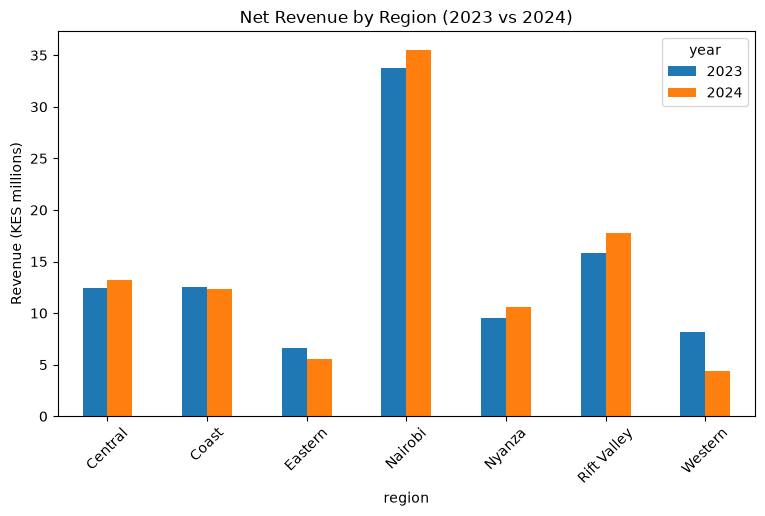

In [51]:
# Net Revenue by Region
(region_rev_year / 1_000_000).plot(kind='bar', figsize=(9,5), title='Net Revenue by Region (2023 vs 2024)')
plt.ylabel('Revenue (KES millions)')
plt.xticks(rotation=45)
plt.show() 

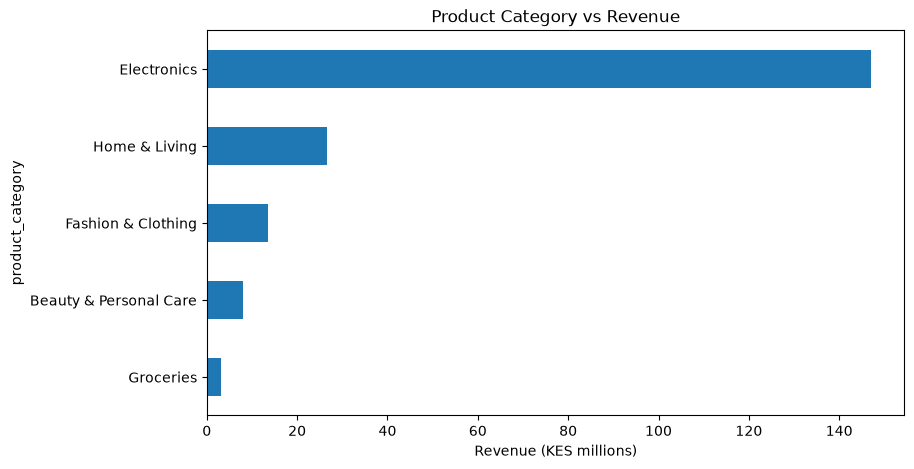

In [52]:
# Net Revenue by Category
(sales.groupby('product_category')['revenue'].sum().sort_values() / 1_000_000).plot(kind='barh', figsize=(9,5), title='Product Category vs Revenue')
plt.xlabel('Revenue (KES millions)')
plt.show()

### Insights
Electronics is far ahead of every other bar at KES 147.1M, which is 74% of net revenue. The other categories are much smaller: Home & Living at 26.6M, Fashion at 13.5M, Beauty at 8M and Groceries at 3.1M.

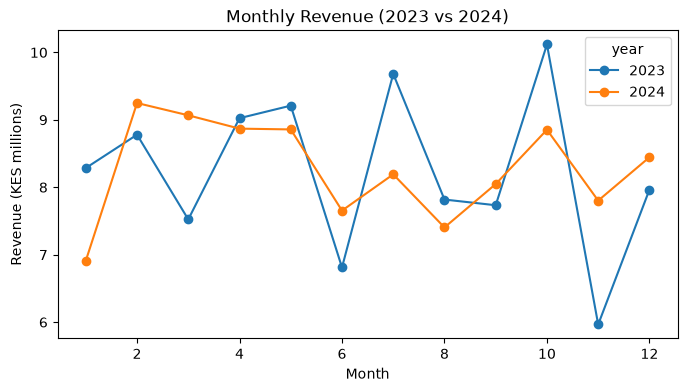

In [53]:
# Monthly Net Revenue
(sales.pivot_table(index='month', columns='year', values='revenue', aggfunc='sum') / 1_000_000).plot(marker='o', figsize=(8,4), title='Monthly Revenue (2023 vs 2024)')
plt.ylabel('Revenue (KES millions)')
plt.xlabel('Month')
plt.show()

### Insights
1. Revenue fluctuated: Both years experienced ups and downs throughout the months. The highest month is October in 2023 and February in 2024 at KES 9.3 milion. 2023 had the lowest revenue: November recorded the lowest revenue at approximately KES 6.0 million.

2. Revenue was more volatile in 2023, while 2024 showed relatively steadier performance in several months.

3. No clear repeating seasonal peak is observed in both years. However, revenue increased in October 2023 and February 2024, suggesting possible peak periods that need more years of data to confirm a seasonal pattern.

In [54]:
print(sales.groupby('month')['revenue'].sum() / 1_000_000)
print(sales.pivot_table(index='month', columns='year', values='revenue', aggfunc='sum'))

month
1     15.195674
2     18.029055
3     16.590502
4     17.893992
5     18.068185
6     14.464815
7     17.873112
8     15.222190
9     15.781464
10    18.970354
11    13.767224
12    16.409228
Name: revenue, dtype: float64
year          2023        2024
month                         
1       8285308.59  6910365.75
2       8779657.67  9249396.95
3       7523365.79  9067135.93
4       9024579.33  8869412.22
5       9210416.01  8857768.57
6       6810948.32  7653867.17
7       9681311.03  8191801.43
8       7817925.64  7404264.54
9       7733655.69  8047808.34
10     10117169.93  8853183.63
11      5965028.56  7802195.03
12      7964085.45  8445142.98


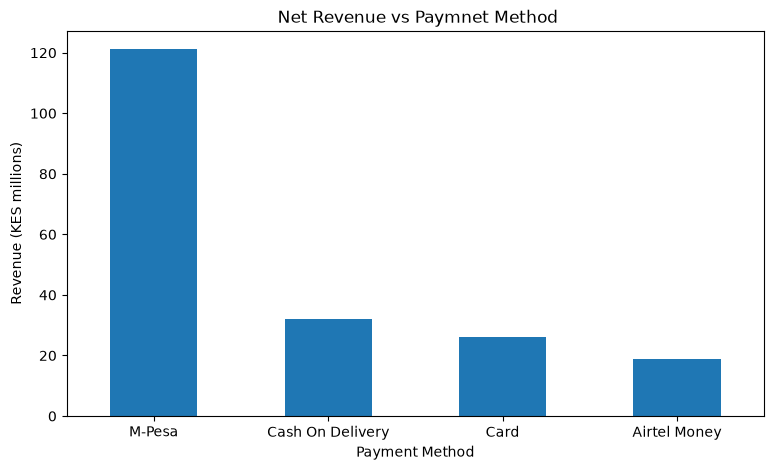

In [55]:
# Net Revenue by Paymnet method
(sales.groupby('payment_method')['revenue'].sum().sort_values(ascending=False) / 1_000_000).plot(kind='bar', figsize=(9,5), title=' Net Revenue vs Paymnet Method')
plt.ylabel('Revenue (KES millions)')
plt.xlabel('Payment Method')
plt.xticks(rotation=0)
plt.show()

In [56]:
print((sales.groupby('payment_method')['revenue'].sum() / 1_000_000).round(1))
print((sales.pivot_table(index='month', columns='year', values='revenue', aggfunc='sum') / 1_000_000).round(1))

payment_method
Airtel Money         19.0
Card                 26.3
Cash On Delivery     31.9
M-Pesa              121.1
Name: revenue, dtype: float64
year   2023  2024
month            
1       8.3   6.9
2       8.8   9.2
3       7.5   9.1
4       9.0   8.9
5       9.2   8.9
6       6.8   7.7
7       9.7   8.2
8       7.8   7.4
9       7.7   8.0
10     10.1   8.9
11      6.0   7.8
12      8.0   8.4


### Insights
1. M-Pesa brings in KES 121.1M, about 61% of net revenue and nearly four times Cash on Delivery (KES 31.9M).

2. Cash on Delivery (KES 31.9M, 16%) is second, ahead of Card (KES 26.3M, 13%) and Airtel Money (KES 19.0M, 10%).

3. Revenue shares are close to order shares (M-Pesa 61.4% of orders, COD 14.6%, Card 14.5%, Airtel 9.5%). COD brings in slightly more revenue than its order share suggests, and Card slightly less.

### **Delivery vs Satisfaction**

In [57]:
delivery_rate = df.dropna(subset=['delivery_days', 'customer_rating'])
print(len(delivery_rate))

3748


3748 is total number of orders that have both delivery days data and customer rating

region
Central        7.06
Rift Valley    7.06
Nyanza         7.03
Eastern        6.94
Western        6.88
Coast          5.99
Nairobi        3.97
Name: delivery_days, dtype: float64


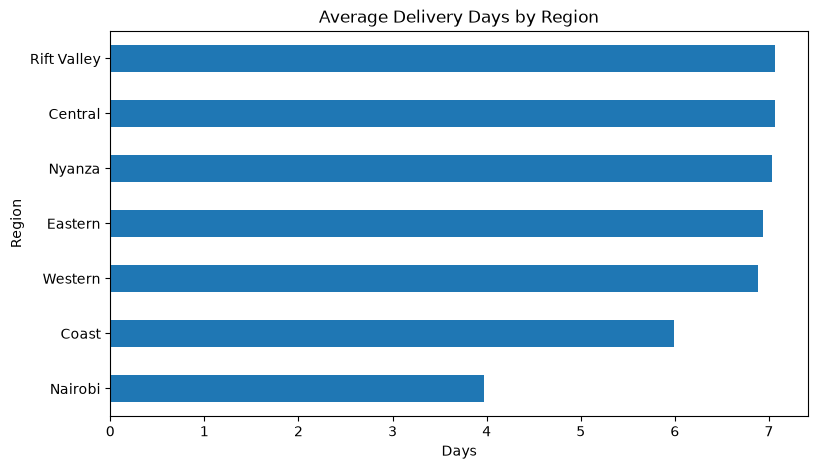

In [58]:
# Average Delivery days by Region
print(delivery_rate.groupby('region')['delivery_days'].mean().round(2).sort_values(ascending=False))

delivery_rate.groupby('region')['delivery_days'].mean().round(2).sort_values().plot(kind='barh', figsize=(9,5), title='Average Delivery Days by Region')
plt.ylabel('Region')
plt.xlabel('Days')
plt.show()

### Average delivery days by region
1. Nairobi is the fastest at 3.97 days. Coast is next at 5.99 days.

2. The other five regions are all slower, at 6.9 to 7.1 days (Western 6.88, Eastern 6.94, Nyanza 7.03, Central and Rift Valley 7.06). That is about 3 days slower than Nairobi.

region
Nairobi        4.25
Coast          4.05
Eastern        3.91
Nyanza         3.91
Rift Valley    3.90
Western        3.88
Central        3.84
Name: customer_rating, dtype: float64


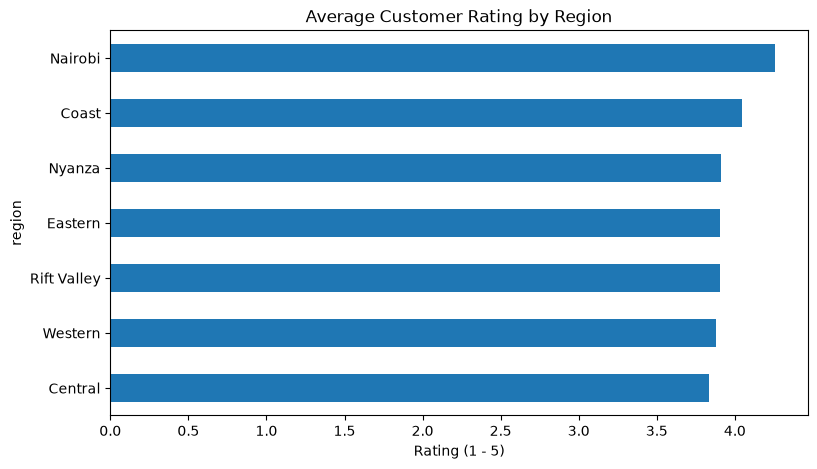

In [59]:
# Average Rating by Region
print(delivery_rate.groupby('region')['customer_rating'].mean().round(2).sort_values(ascending=False))

delivery_rate.groupby('region')['customer_rating'].mean().sort_values().plot(kind='barh', figsize=(9,5), title= 'Average Customer Rating by Region')
plt.xlabel('Rating (1 - 5)')
plt.show()

### Average rating by region
1. Nairobi has the highest rating (4.25), followed by Coast (4.05). The other five regions sit between 3.84 and 3.91, so they are close together; the differences are too small to read anything into.

               count      mean
delivery_days                 
1.0               92  4.529348
2.0              161  4.414286
3.0              298  4.388255
4.0              423  4.251300
5.0              630  4.147619
6.0              698  4.051003
7.0              549  3.890346
8.0              438  3.790183
9.0              326  3.618098
10.0             133  3.454887


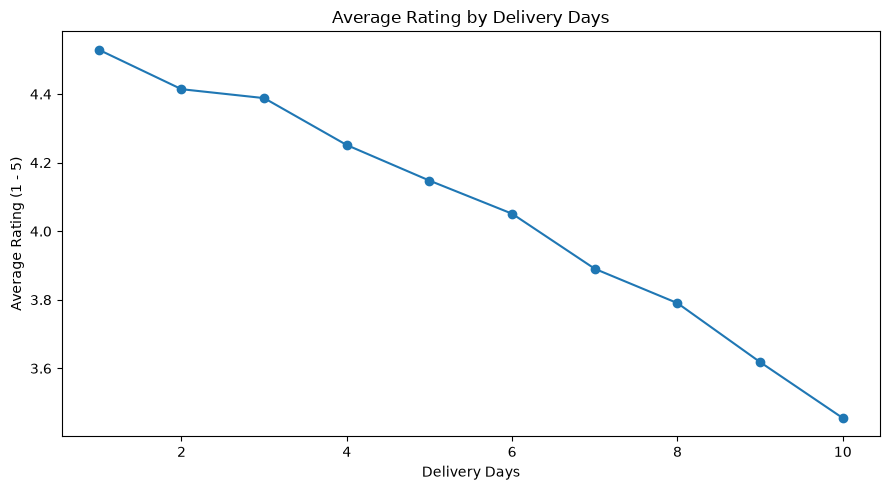

Correlation: -0.3


In [60]:
# Average Rating by Delivery Speed
print(delivery_rate.groupby('delivery_days')['customer_rating'].agg(['count', 'mean']))

delivery_rate.groupby('delivery_days')['customer_rating'].mean().plot(marker='o', figsize=(9,5), title='Average Rating by Delivery Days')
plt.xlabel('Delivery Days')
plt.ylabel('Average Rating (1 - 5)')
plt.tight_layout()
plt.show()

print('Correlation:', delivery_rate['delivery_days'].corr(delivery_rate['customer_rating']).round(2))

### Average rating by delivery day
1. Ratings fall steadily as delivery gets slower, from 4.53 at 1 day to 3.45 at 10 days.

2. Most orders are delivered in 5 to 7 days (630, 698 and 549 orders). The smallest groups are 1 day (92 orders) and 10 days (133 orders), so those averages are less reliable.

3. This matches the correlation of -0.3.

In [61]:
print(delivery_rate.groupby('region')['customer_rating'].mean().round(2).sort_values())
print(delivery_rate.groupby('region')['delivery_days'].mean().round(2).sort_values())

region
Central        3.84
Western        3.88
Rift Valley    3.90
Eastern        3.91
Nyanza         3.91
Coast          4.05
Nairobi        4.25
Name: customer_rating, dtype: float64
region
Nairobi        3.97
Coast          5.99
Western        6.88
Eastern        6.94
Nyanza         7.03
Central        7.06
Rift Valley    7.06
Name: delivery_days, dtype: float64


### **Summary findings for Delivery vs Satisfaction**

Delivery is about 3 days faster in Nairobi (4.0 days) than in most other regions (about 7 days), and Nairobi has the highest ratings (4.25 vs. 3.84 to 3.91). Across 3,748 rated, delivered orders, longer delivery goes with lower ratings. This supports leadership’s hypothesis, as an association and not proven cause.

### **Cancellation and Returns**

In [62]:
# Basic Overview
print((df.groupby('region')['is_cancelled_or_returned'].mean() * 100).round(2).sort_values(ascending=False))
print((df.groupby('payment_method')['is_cancelled_or_returned'].mean() * 100).round(2).sort_values(ascending=False))
print((df.groupby('product_category')['is_cancelled_or_returned'].mean() * 100).round(2).sort_values(ascending=False))

region
Coast          13.30
Nairobi        13.30
Nyanza         13.21
Western        12.91
Eastern        12.18
Central        11.59
Rift Valley    10.39
Name: is_cancelled_or_returned, dtype: float64
payment_method
Card                16.16
Airtel Money        13.03
M-Pesa              11.91
Cash On Delivery    11.13
Name: is_cancelled_or_returned, dtype: float64
product_category
Groceries                 13.82
Beauty & Personal Care    12.77
Electronics               12.51
Fashion & Clothing        12.22
Home & Living             11.79
Name: is_cancelled_or_returned, dtype: float64


             count  sum
region                 
Central        621   72
Coast          707   94
Eastern        312   38
Nairobi       1677  223
Nyanza         530   70
Rift Valley    789   82
Western        364   47


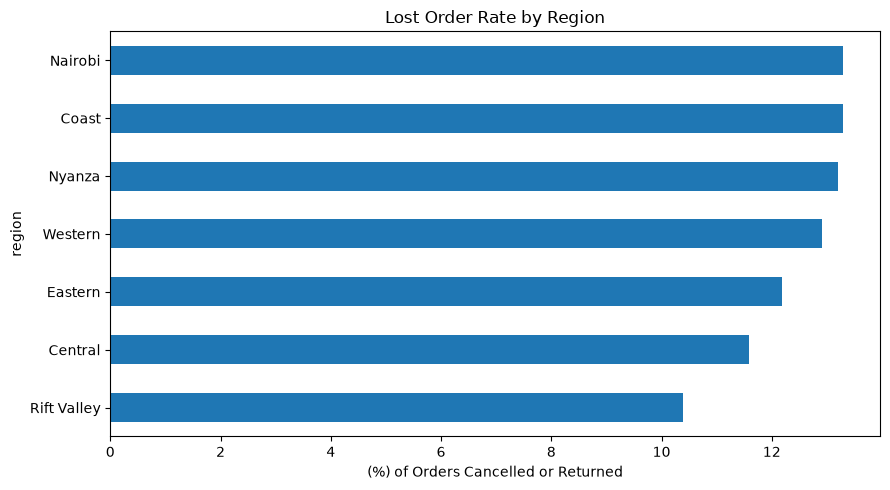

In [63]:
# Lost Order rate by Region
print(df.groupby('region')['is_cancelled_or_returned'].agg(['count', 'sum']))

(df.groupby('region')['is_cancelled_or_returned'].mean() * 100).sort_values().plot(kind='barh', figsize=(9,5), title='Lost Order Rate by Region')
plt.xlabel('(%) of Orders Cancelled or Returned')
plt.tight_layout()
plt.show()

### Lost-Order Rate by Region

1. Rates range from 10.4% (Rift Valley, 82 of 729 orders) to 13.3% (Coast, 94 of 707 and Nairobi, 223 of 1677), a gap of about 3 points around the overall 12.5%. Western (12.9%) and Eastern (12.2%) are mid-range, so their revenue declines aren’t explained by more lost orders.

2. Nairobi has the fastest delivery but one of the highest lost-order rates, so delivery speed doesn’t line up with lost orders.

                  count  sum
payment_method              
Airtel Money        476   62
Card                724  117
Cash On Delivery    728   81
M-Pesa             3072  366


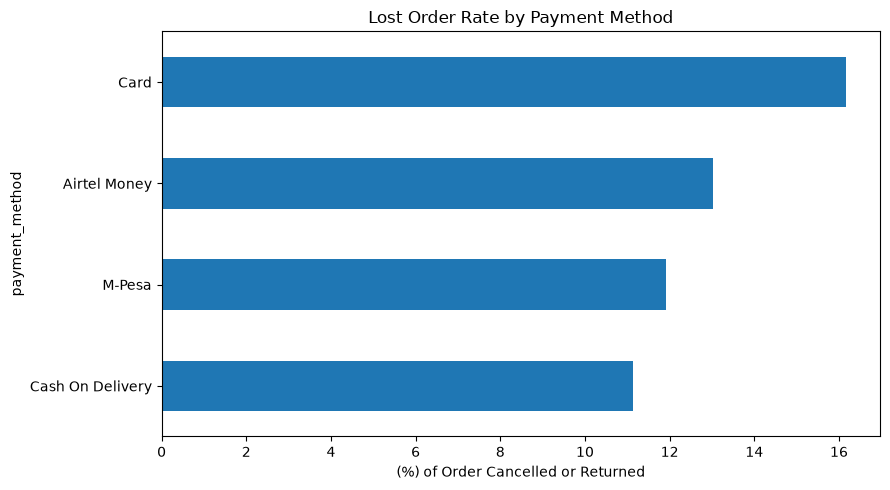

In [64]:
# Lost Order Rate by Payment method
print(df.groupby('payment_method')['is_cancelled_or_returned'].agg(['count', 'sum']))

(df.groupby('payment_method')['is_cancelled_or_returned'].mean() * 100).sort_values().plot(kind='barh', figsize=(9,5), title='Lost Order Rate by Payment Method')
plt.xlabel('(%) of Order Cancelled or Returned')
plt.tight_layout()
plt.show()

### Lost-Order Rate by Payment method

1. Card is highest at 16.2%, followed by Airtel Money (13.0%), M-Pesa (11.9%) and Cash On Delivery (11.1%). Card is about 5 points above Cash On Delivery, which has the lowest rate.

                  is_cancelled  is_returned
payment_method                             
Card                      9.94         6.22
Airtel Money              7.56         5.46
M-Pesa                    7.16         4.75
Cash On Delivery          6.73         4.40


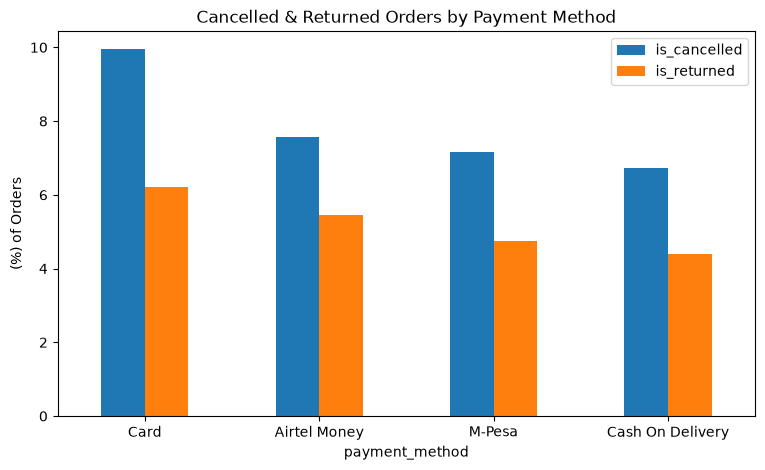

In [65]:
# Separate is_cancelled_or_returned column to get both Cancelled and Returned values
df['is_cancelled'] = df['order_status'] == 'Cancelled'
df['is_returned'] = df['order_status'] == 'Returned'

rates = df.groupby('payment_method')[['is_cancelled', 'is_returned']].mean() * 100
rates = rates.sort_values(by='is_cancelled', ascending=False)
print(rates.round(2))

rates.plot(kind='bar', figsize=(9,5), stacked=False, title='Cancelled & Returned Orders by Payment Method')
plt.ylabel('(%) of Orders')
plt.xticks(rotation=0)
plt.tight_layout
plt.show()

### Cancelled vs. Returned Orders by Payment method
1. Cancellations are more common than returns for every payment method, at roughly 60% of lost orders (Card is higher on both types.).

2. Card is highest at 16.2% (117 of 724 orders), followed by Airtel Money 13.0% (62 of 476), M-Pesa 11.9% (366 of 3,072) and Cash On Delivery 11.1% (81 of 728).

                        count  sum
product_category                  
Beauty & Personal Care    893  114
Electronics              1367  171
Fashion & Clothing       1268  155
Groceries                 615   85
Home & Living             857  101


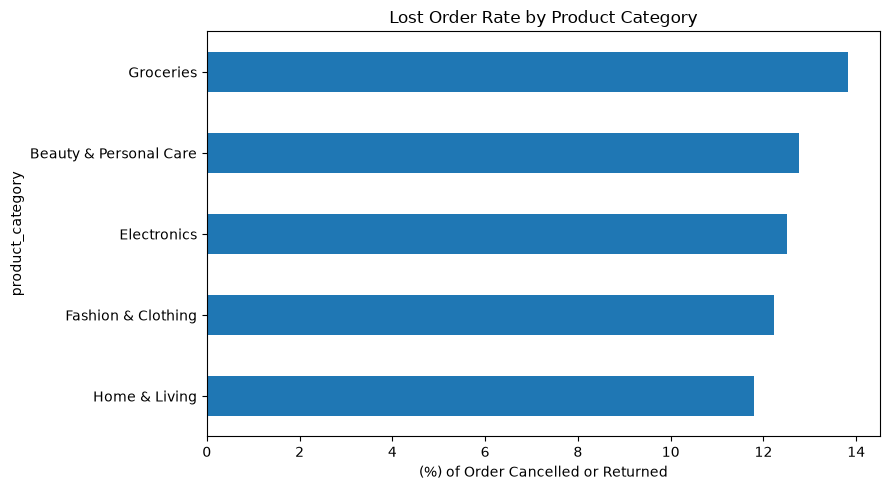

In [66]:
# Lost-order rate by category
print(df.groupby('product_category')['is_cancelled_or_returned'].agg(['count', 'sum']))

(df.groupby('product_category')['is_cancelled_or_returned'].mean() * 100).sort_values().plot(kind='barh', figsize=(9,5), title='Lost Order Rate by Product Category')
plt.xlabel('(%) of Order Cancelled or Returned')
plt.tight_layout()
plt.show()

### Lost-Order Rate by Category
Rates range only from 11.8% (Home & Living, 101 of 857) to 13.8% (Groceries, 85 of 615), so there is no strong category pattern. Groceries is the smallest category (615 orders), so its rate is the least reliable.

### **Summary Findings Cancellations and Returns**
1. About 12.5% of orders are lost (7.5% cancelled, 5.0% returned), and the rate is fairly even across regions (10.4% to 13.3%) and categories (11.8% to 13.8%). Payment method shows the clearest difference: Card orders are lost most often (16.2%) and Cash On Delivery least (11.1%). Card is higher on both cancellations and returns, and cancellations outnumber returns for every payment method.